<a href="https://colab.research.google.com/github/Pranavhub811/job-resume-anayliser/blob/main/ReviewSense_Sentiment_Analyz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import requests
from io import BytesIO

# Download dataset information from Zenodo
api_url = "https://zenodo.org/api/records/3549704"
response = requests.get(api_url, timeout=60)
response.raise_for_status()

record = response.json()

# Find the CSV file automatically
csv_files = [
    f for f in record["files"]
    if f["key"].lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("No CSV dataset was found in the Zenodo record.")

file_info = csv_files[0]
print("Dataset file:", file_info["key"])

# Download and read CSV
download_url = file_info["links"]["self"]
file_response = requests.get(download_url, timeout=120)
file_response.raise_for_status()

df = pd.read_csv(BytesIO(file_response.content))

print("Dataset downloaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset file: Amazon Review Data Web Scrapping - Amazon Review Data Web Scrapping.csv
Dataset downloaded successfully!
Shape: (60889, 6)
Columns: ['Unique_ID', 'Category', 'Review_Header', 'Review_text', 'Rating', 'Own_Rating']


,Unique_ID,Category,Review_Header,Review_text,Rating,Own_Rating
0,136040,smartTv,Nice one,I liked it,5,Positive
1,134236,mobile,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,5,Positive
2,113945,books,Four Stars,"Awesome book at reasonable price, must buy ......",4,Positive
3,168076,smartTv,Nice quality,good,5,Positive
4,157302,books,Nice book,"The book is fine,not bad,contains nice concept...",3,Neutral


In [10]:
import numpy as np

# Normalize column names for easier matching
column_map = {
    str(col).strip().lower().replace(" ", "_"): col
    for col in df.columns
}

def find_column(candidates):
    for candidate in candidates:
        if candidate in column_map:
            return column_map[candidate]
    return None

rating_col = find_column([
    "rating", "ratings", "overall", "review_rating", "stars"
])

text_col = find_column([
    "review_text", "reviewtext", "review", "review_body",
    "reviewbody", "content", "text"
])

title_col = find_column([
    "review_header", "review_title", "summary", "title"
])

if rating_col is None or text_col is None:
    raise ValueError(
        "Could not identify rating and review columns. "
        f"Available columns: {df.columns.tolist()}"
    )

# Combine title and review text when a title column exists
if title_col is not None:
    df["review"] = (
        df[title_col].fillna("").astype(str) + " " +
        df[text_col].fillna("").astype(str)
    ).str.strip()
else:
    df["review"] = df[text_col].fillna("").astype(str).str.strip()

df["rating"] = pd.to_numeric(df[rating_col], errors="coerce")
df = df.dropna(subset=["rating"])
df = df[df["review"].str.len() >= 10].copy()

# Map star ratings to sentiment
df["sentiment"] = np.select(
    [
        df["rating"].between(1, 2, inclusive="both"),
        df["rating"].eq(3),
        df["rating"].between(4, 5, inclusive="both")
    ],
    ["Negative", "Neutral", "Positive"],
    default="Unknown"
)

df = df[df["sentiment"] != "Unknown"]
df = df.drop_duplicates(subset=["review"])
df = df[["review", "rating", "sentiment"]].reset_index(drop=True)

print("Clean dataset size:", len(df))
print("\nSentiment distribution:")
display(df["sentiment"].value_counts().to_frame("Reviews"))

display(df.head())

Clean dataset size: 54821

Sentiment distribution:


,Reviews
sentiment,
Positive,41875
Negative,8898
Neutral,4048


,review,rating,sentiment
0,Nice one I liked it,5,Positive
1,Huge battery life with amazing display I bough...,5,Positive
2,"Four Stars Awesome book at reasonable price, m...",4,Positive
3,Nice quality good,5,Positive
4,"Nice book The book is fine,not bad,contains ni...",3,Neutral


In [11]:
MAX_PER_CLASS = 10000  # Up to 30,000 reviews in total

class_counts = df["sentiment"].value_counts()
print("Available reviews per class:")
print(class_counts)

if len(class_counts) != 3:
    raise ValueError("Expected all three sentiment classes.")

sampled_parts = []

for label in ["Negative", "Neutral", "Positive"]:
    part = df[df["sentiment"] == label]
    sampled_parts.append(
        part.sample(
            n=min(MAX_PER_CLASS, len(part)),
            random_state=42
        )
    )

data = (
    pd.concat(sampled_parts)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("\nTraining dataset size:", len(data))
display(data["sentiment"].value_counts().to_frame("Reviews"))

Available reviews per class:
sentiment
Positive    41875
Negative     8898
Neutral      4048
Name: count, dtype: int64

Training dataset size: 22946


,Reviews
sentiment,
Positive,10000
Negative,8898
Neutral,4048


In [12]:
from sklearn.model_selection import train_test_split

X = data["review"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 18356
Testing samples: 4590


In [13]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

features = FeatureUnion([
    (
        "word_features",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=200000,
            sublinear_tf=True
        )
    ),
    (
        "character_features",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            max_features=100000,
            sublinear_tf=True
        )
    )
])

model = Pipeline([
    ("features", features),
    ("classifier", LinearSVC(class_weight="balanced"))
])

print("Model pipeline created!")

Model pipeline created!


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=50000,
            min_df=2,
            sublinear_tf=True
        )
    ),
    ("classifier", LinearSVC(C=1.0))
])

best_model = model.fit(X_train, y_train)

print("Fast TF-IDF + SVM model trained successfully!")

Fast TF-IDF + SVM model trained successfully!


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy:        {accuracy:.4f} ({accuracy:.2%})")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall:    {macro_recall:.4f}")
print(f"Macro F1-score:  {macro_f1:.4f}")

print("\nClassification report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

Accuracy:        0.7906 (79.06%)
Macro Precision: 0.7273
Macro Recall:    0.7041
Macro F1-score:  0.7070

Classification report:

              precision    recall  f1-score   support

    Negative       0.79      0.88      0.83      1780
     Neutral       0.54      0.34      0.42       810
    Positive       0.85      0.90      0.87      2000

    accuracy                           0.79      4590
   macro avg       0.73      0.70      0.71      4590
weighted avg       0.77      0.79      0.78      4590



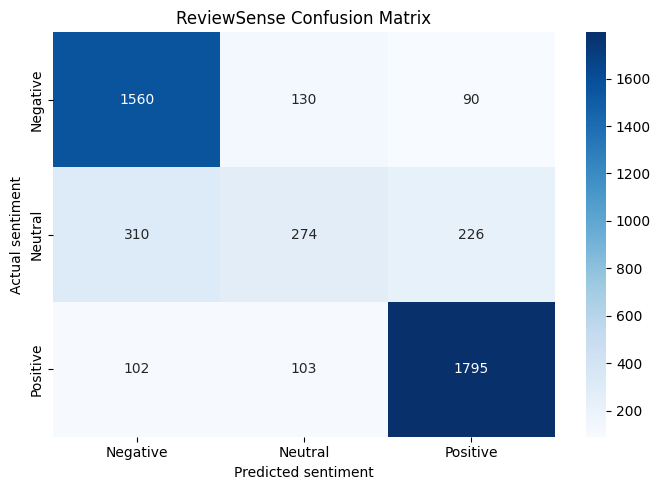

In [16]:
labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("ReviewSense Confusion Matrix")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

In [17]:
metrics = pd.DataFrame([{
    "Model": "TF-IDF Word + Character Features + Linear SVM",
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Training Samples": len(X_train),
    "Testing Samples": len(X_test)
}])

display(metrics.round(4))
metrics.to_csv("/content/ReviewSense_evaluation.csv", index=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Samples,Testing Samples
0,TF-IDF Word + Character Features + Linear SVM,0.7906,0.7273,0.7041,0.707,18356,4590


In [18]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

negative_texts = data.loc[
    data["sentiment"] == "Negative", "review"
]

topic_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_features=20000,
    sublinear_tf=True
)

negative_matrix = topic_vectorizer.fit_transform(negative_texts)

n_topics = 5

topic_model = NMF(
    n_components=n_topics,
    random_state=42,
    max_iter=300,
    init="nndsvda"
)

topic_model.fit(negative_matrix)

terms = topic_vectorizer.get_feature_names_out()

for topic_number, component in enumerate(topic_model.components_):
    top_indices = component.argsort()[-10:][::-1]
    top_words = [terms[i] for i in top_indices]

    print(f"Topic {topic_number + 1}: {', '.join(top_words)}")

Topic 1: product, working, worst, phone, amazon, service, worst product, stopped, defective, stopped working
Topic 2: good, quality, poor, camera, battery, sound, camera quality, phone, quality good, quality poor
Topic 3: buy, don, don buy, worst, dont buy, buy product, dont, product don, buy phone, buy don
Topic 4: bad, bad product, bad bad, bad quality, bad experience, product, experience, quality bad, quality, product bad
Topic 5: waste, money, waste money, money waste, worth, don waste, waste product, dont, total, product waste


In [19]:
def predict_sentiment(review):
    review = str(review).strip()

    if len(review) < 3:
        print("Please enter a longer customer review.")
        return None

    sentiment = best_model.predict([review])[0]

    print("\nCustomer Review:", review)
    print("Predicted Sentiment:", sentiment)

    if sentiment == "Negative":
        review_vector = topic_vectorizer.transform([review])
        topic_scores = topic_model.transform(review_vector)[0]

        topic_index = int(np.argmax(topic_scores))
        component = topic_model.components_[topic_index]

        top_indices = component.argsort()[-6:][::-1]
        topic_words = [terms[i] for i in top_indices]

        print(f"Possible complaint topic: Topic {topic_index + 1}")
        print("Related terms:", ", ".join(topic_words))
        print("Note: Check the topic's top words to interpret its meaning.")

    return sentiment


review = input("Enter a customer review: ")
prediction = predict_sentiment(review)

Enter a customer review: average

Customer Review: average
Predicted Sentiment: Neutral


In [20]:
predict_sentiment(
    "The battery loses charge quickly and the phone keeps shutting down."
)

predict_sentiment(
    "Amazing product quality, excellent performance and fast delivery."
)

predict_sentiment(
    "The product is average and does what it is supposed to do."
)


Customer Review: The battery loses charge quickly and the phone keeps shutting down.
Predicted Sentiment: Negative
Possible complaint topic: Topic 2
Related terms: good, quality, poor, camera, battery, sound
Note: Check the topic's top words to interpret its meaning.

Customer Review: Amazing product quality, excellent performance and fast delivery.
Predicted Sentiment: Positive

Customer Review: The product is average and does what it is supposed to do.
Predicted Sentiment: Negative
Possible complaint topic: Topic 1
Related terms: product, working, worst, phone, amazon, service
Note: Check the topic's top words to interpret its meaning.


'Negative'

In [21]:
import joblib
import os
from google.colab import files

joblib.dump(best_model, "/content/reviewsense_model.joblib")
joblib.dump(topic_vectorizer, "/content/reviewsense_topic_vectorizer.joblib")
joblib.dump(topic_model, "/content/reviewsense_topic_model.joblib")

print("All models saved successfully!")

All models saved successfully!


In [22]:
files.download("/content/reviewsense_model.joblib")
files.download("/content/reviewsense_topic_vectorizer.joblib")
files.download("/content/reviewsense_topic_model.joblib")
files.download("/content/ReviewSense_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>